In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("D:\DA - projects\END-TO-END\Hotel-Booking-Demand\data\hotel_bookings_cleaned.csv")

In [4]:
# Total Bookings
len(df)

87009

Text(0, 0.5, 'Bookings')

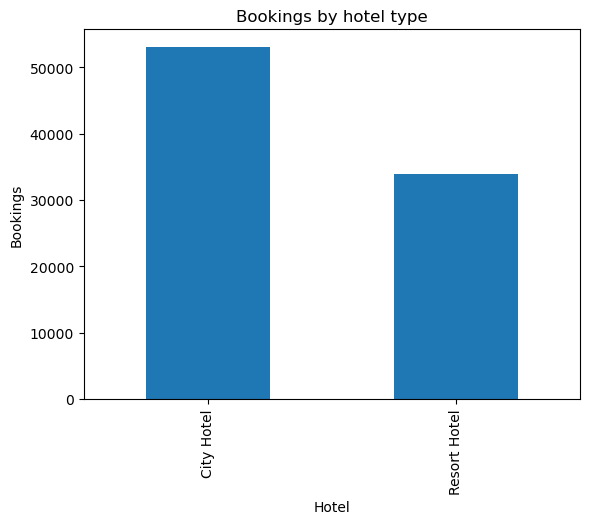

In [7]:
# Do customers prefer City Hotels or Resort Hotels?

df["hotel"].value_counts().plot(kind="bar")
plt.title("Bookings by hotel type")
plt.xlabel("Hotel")
plt.ylabel("Bookings")

In [9]:
df.groupby("hotel")["adr"].mean().round(2)

hotel
City Hotel      111.30
Resort Hotel     99.06
Name: adr, dtype: float64

In [11]:
(df.groupby("hotel")["is_canceled"].mean() * 100).round(2)

hotel
City Hotel      30.07
Resort Hotel    23.48
Name: is_canceled, dtype: float64

In [13]:
# Cancellation rate

(df["is_canceled"].value_counts(normalize=True)*100).round(2)

is_canceled
0    72.5
1    27.5
Name: proportion, dtype: float64

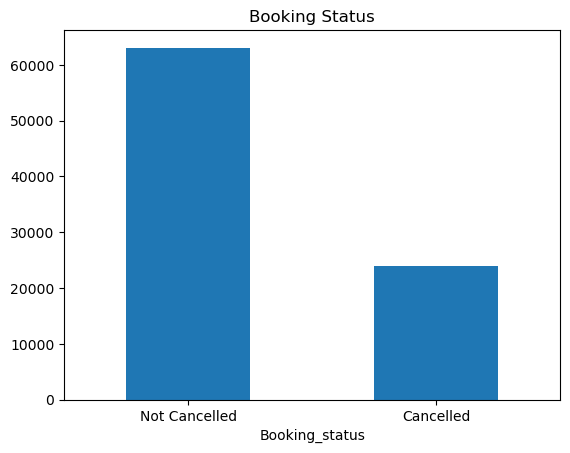

In [18]:
df["is_canceled"].value_counts().plot(kind="bar")
plt.title("Booking Status")
plt.xticks([0,1],["Not Cancelled", "Cancelled"], rotation=0)
plt.xlabel("Booking_status")
plt.show()

In [29]:
# When hotel demands are high

monthly = (df["arrival_date"].dt.month.value_counts().sort_index())

monthly

arrival_date
1      4667
2      6065
3      7471
4      7879
5      8329
6      7745
7     10011
8     11210
9      6671
10     6905
11     4967
12     5089
Name: count, dtype: int64

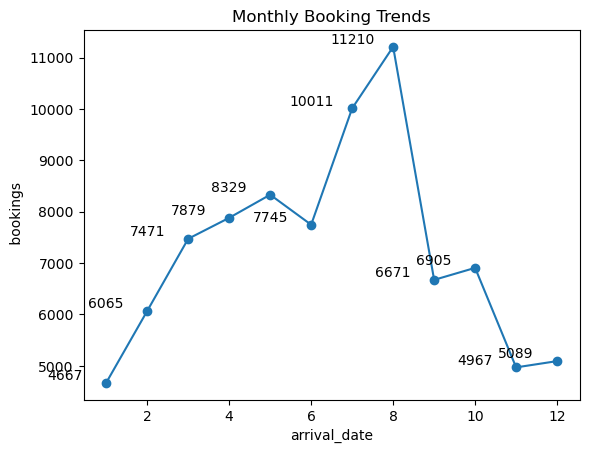

In [28]:
monthly.plot(kind="line", marker="o")

for x,y in enumerate(monthly):
    plt.text(x, y, str(y), ha="center", va="bottom")

plt.title("Monthly Booking Trends")
plt.ylabel(" bookings")
plt.show()

In [33]:
monthly_summary = df.groupby(df["arrival_date"].dt.month_name()).agg(
    bookings = ("is_canceled", "size"),
    cancellation_rate = ("is_canceled", "mean"),
    avg_adr = ("adr", "mean")
)

monthly_summary["cancellation_rate"] *= 100
monthly_summary

,bookings,cancellation_rate,avg_adr
arrival_date,,,
April,7879,30.435334,103.743676
August,11210,32.212310,151.249018
December,5089,26.881509,81.808689
February,6065,23.182193,74.880477
January,4667,22.134133,70.248665
July,10011,31.834982,135.905562
June,7745,30.342156,119.894425
March,7471,24.334092,81.169177
May,8329,29.235202,111.298663


In [34]:
# How far in advance do customers book?
df["lead_time"].describe()

count    87009.000000
mean        79.861566
std         86.007673
min          0.000000
25%         11.000000
50%         49.000000
75%        125.000000
max        737.000000
Name: lead_time, dtype: float64

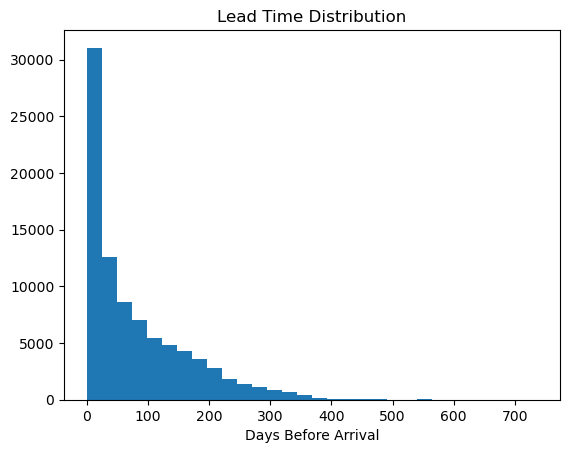

In [35]:
plt.hist(df["lead_time"],bins=30)
plt.title("Lead Time Distribution")
plt.xlabel("Days Before Arrival")
plt.show()

In [37]:
df.groupby("is_canceled")["lead_time"].mean()

is_canceled
0     70.101281
1    105.593932
Name: lead_time, dtype: float64

In [38]:
# How long do guests stay?

df["total_stay_nights"].describe()

count    87009.000000
mean         3.628613
std          2.744639
min          0.000000
25%          2.000000
50%          3.000000
75%          5.000000
max         69.000000
Name: total_stay_nights, dtype: float64

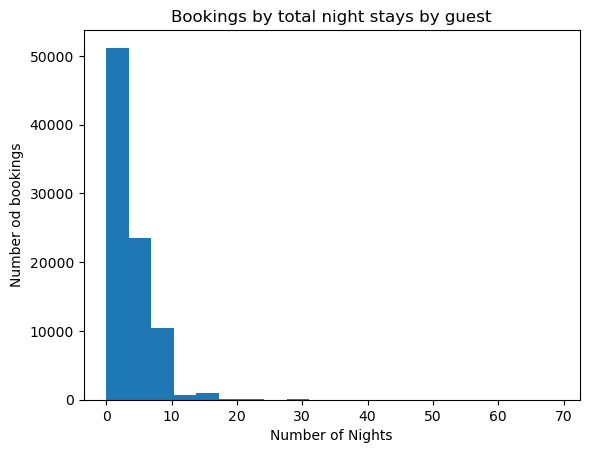

In [40]:
plt.hist(df["total_stay_nights"],bins=20)
plt.title("Bookings by total night stays by guest")
plt.xlabel("Number of Nights")
plt.ylabel("Number od bookings")
plt.show()

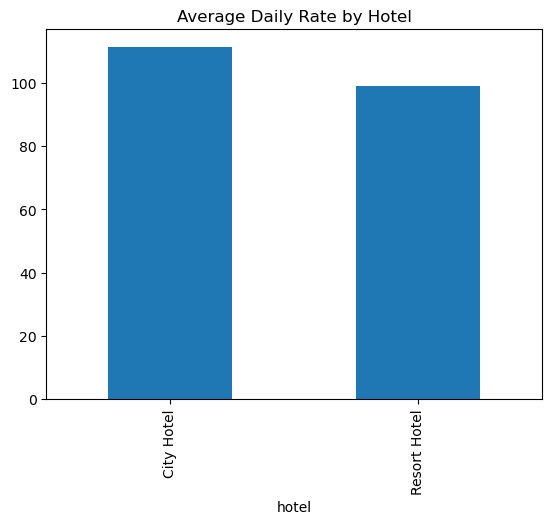

In [42]:
# Which hotel earns higher room rates?

df.groupby("hotel")["adr"].mean().plot(kind="bar")
plt.title("Average Daily Rate by Hotel")
plt.show()

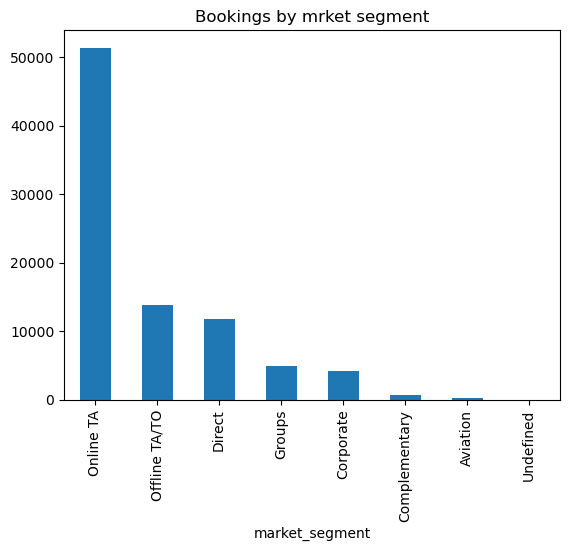

In [44]:
# Which customer segment brings the most bookings?

df["market_segment"].value_counts().plot(kind="bar")
plt.title("Bookings by mrket segment")
plt.show()

In [45]:
df.groupby("market_segment")["is_canceled"].mean() * 100

market_segment
Aviation          19.911504
Complementary     12.209302
Corporate         12.119048
Direct            14.722151
Groups            27.067669
Offline TA/TO     14.836474
Online TA         35.370839
Undefined        100.000000
Name: is_canceled, dtype: float64

In [46]:
# Which customer types are most valuable?

df["customer_type"].value_counts()

customer_type
Transient          71725
Transient-Party    11610
Contract            3134
Group                540
Name: count, dtype: int64

In [49]:
cancellation_by_customer = ( df.groupby("customer_type")["is_canceled"].mean() * 100)
cancellation_by_customer

customer_type
Contract           16.336950
Group               9.814815
Transient          30.119205
Transient-Party    15.150732
Name: is_canceled, dtype: float64

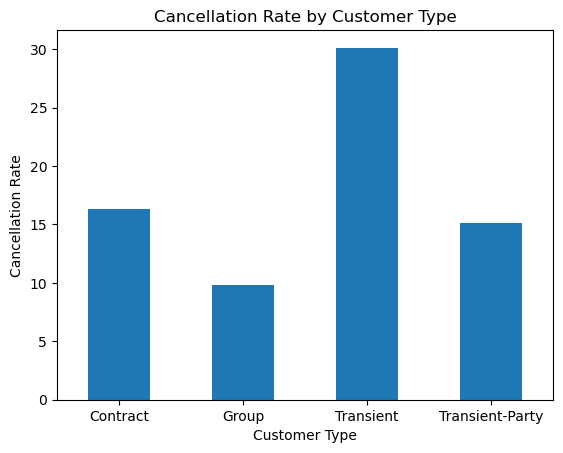

In [52]:
cancellation_by_customer.plot(kind="bar")
plt.title("Cancellation Rate by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Cancellation Rate")
plt.xticks(rotation=0)
plt.show()

In [53]:
# Which booking channel performs best?

df["distribution_channel"].describe()

count     87009
unique        5
top       TA/TO
freq      68841
Name: distribution_channel, dtype: object

In [54]:
df.groupby("distribution_channel")["is_canceled"].mean() * 100

distribution_channel
Corporate    12.761754
Direct       14.821981
GDS          19.889503
TA/TO        30.978632
Undefined    80.000000
Name: is_canceled, dtype: float64

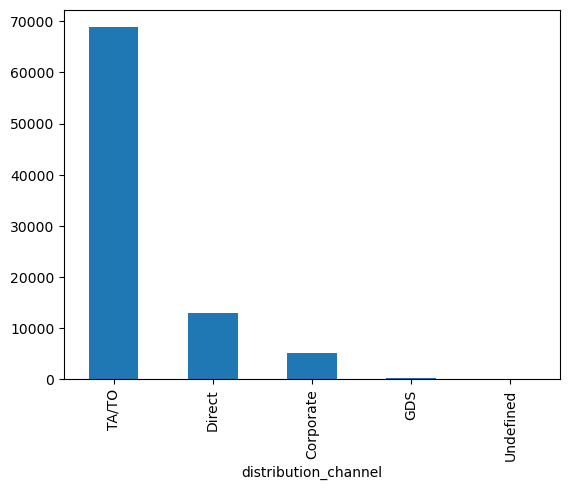

In [56]:
df["distribution_channel"].value_counts().plot(kind="bar")
plt.show()